<a href="https://colab.research.google.com/github/UtkarshWoc/AI_and_Society_Assignment/blob/main/Adult_Income_Audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Auditing a Predictive Income Model — Bias, Confounds & Fairness Trade-offs
**Dataset:** Adult Census Income (UCI)
**Random seed (`random_state`):** `829` — last three digits of roll **S24CSEU2829**
**Split:** 70% train / 30% test

This notebook is fully reproducible: running it top-to-bottom regenerates **every number, table and figure** cited in the report. All figures are written to `figures/` and all computed numbers to `output/results.json`.

**Contents**
0. Data loading
1. Preprocessing (missing values, encoding, scaling, outliers)
2. Part 1 — Model A (OLS) vs Model B (Logistic) and their disagreement
3. Part 2.1 — Simpson's-paradox / subgroup-divergence hunt
4. Part 2.2 — Omitted-variable bias
5. Part 2.3 — Adversarial (confident-but-wrong) subset
6. Part 2.4 — Fairness trade-off across thresholds

In [1]:
%matplotlib inline
import json, os, io, warnings, urllib.request
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
from scipy.linalg import qr as _qr
import statsmodels.api as sm

warnings.filterwarnings("ignore")
SEED = 829
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True); os.makedirs("output", exist_ok=True)
R = {}   # every reported number is collected here and saved to output/results.json
print("seed =", SEED)

seed = 829


## 0. Data loading

The 15 standard columns of the Adult data set. The loader first looks for a local copy
(`data/adult.csv`, committed to the repo); if absent it downloads and combines the original
`adult.data` + `adult.test` from the UCI repository, stripping the stray header row and the
trailing `.` that `adult.test` appends to the income label. The combined file has **48,842** records.

In [2]:
COLS = ['age','workclass','fnlwgt','education','education-num','marital-status',
        'occupation','relationship','race','sex','capital-gain','capital-loss',
        'hours-per-week','native-country','income']

def load_adult():
    if os.path.exists("data/adult.csv"):
        return pd.read_csv("data/adult.csv", header=None, names=COLS,
                           skipinitialspace=True, na_values='?')
    base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
    def grab(fn, skip):
        raw = urllib.request.urlopen(base+fn, timeout=60).read().decode("utf-8", "ignore")
        return pd.read_csv(io.StringIO(raw), header=None, names=COLS, skiprows=skip,
                           skipinitialspace=True, na_values='?', comment='|')
    tr = grab("adult.data", 0)
    te = grab("adult.test", 1)   # first line of adult.test is a comment
    df = pd.concat([tr, te], ignore_index=True)
    os.makedirs("data", exist_ok=True)
    df.to_csv("data/adult.csv", header=False, index=False)
    return df

df = load_adult()
df['income'] = df['income'].astype(str).str.replace('.', '', regex=False).str.strip()
R['n_raw'] = int(len(df))
print("raw records:", len(df))
print("income labels:", df['income'].value_counts().to_dict())
df.head()

raw records: 48842
income labels: {'<=50K': 37155, '>50K': 11687}


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 1. Preprocessing

**Missing values.** Only `workclass`, `occupation` and `native-country` contain the UCI sentinel
`?`. We read it as `NaN` and **drop** every row with any missing value — a clean, imputation-free
choice that removes ≈7.4% of rows and avoids injecting a single modal value into a high-cardinality
field such as `occupation`.

**Target.** `income` → `1` if `>50K`, else `0`.

**Redundant / non-predictive columns.** We drop `fnlwgt` (a census *sampling weight*, i.e. how many
people the row represents — not an attribute of the individual) and the string `education` (perfectly
redundant with the ordinal `education-num`).

**Categorical encoding.** One-hot with `drop_first=True` (reference level dropped) so the design
matrix is identifiable and coefficients read as contrasts against a baseline.

**Feature scaling.** The five continuous features (`age`, `education-num`, `capital-gain`,
`capital-loss`, `hours-per-week`) are standardised with a `StandardScaler` **fit on the training
split only** (no leakage). Dummies are left as 0/1.

**Outliers.** `capital-gain` is right-skewed with a top-coded sentinel of `99999` (a few hundred
rows) and most values `0`; `age` (17–90) and `hours-per-week` (1–99) are also top-coded. These are
legitimate census top-codes, not data-entry errors, and `capital-gain` is strongly predictive, so we
**retain** them and rely on standardisation to limit their leverage.

In [3]:
# ---- missing values ----
miss = df.isna().sum()
R['missing_counts'] = {k:int(v) for k,v in miss[miss>0].items()}
R['n_rows_with_missing'] = int(df.isna().any(axis=1).sum())
R['pct_rows_with_missing'] = round(100*R['n_rows_with_missing']/len(df),2)
print("missing per column:", R['missing_counts'])
print(f"rows with any missing: {R['n_rows_with_missing']} ({R['pct_rows_with_missing']}%)")

df = df.dropna().reset_index(drop=True)
R['n_after_dropna'] = int(len(df))

# ---- target ----
df['target'] = (df['income']=='>50K').astype(int)
R['positive_rate_overall'] = round(float(df['target'].mean()),4)
print("rows after dropna:", R['n_after_dropna'], "| overall P(>50K):", R['positive_rate_overall'])

# ---- drop redundant / non-predictive ----
df = df.drop(columns=['fnlwgt','education','income'])

NUM = ['age','education-num','capital-gain','capital-loss','hours-per-week']
CAT_FULL = ['workclass','marital-status','occupation','relationship','race','sex','native-country']

# ---- outlier audit (documented, retained) ----
R['outlier_audit'] = {
  'capital-gain_max': int(df['capital-gain'].max()),
  'capital-gain_eq_99999_count': int((df['capital-gain']==99999).sum()),
  'capital-gain_zero_pct': round(100*float((df['capital-gain']==0).mean()),2),
  'age_min': int(df.age.min()), 'age_max': int(df.age.max()),
  'hours_min': int(df['hours-per-week'].min()), 'hours_max': int(df['hours-per-week'].max())}
print("outlier audit:", R['outlier_audit'])

missing per column: {'workclass': 2799, 'occupation': 2809, 'native-country': 857}
rows with any missing: 3620 (7.41%)
rows after dropna: 45222 | overall P(>50K): 0.2478
outlier audit: {'capital-gain_max': 99999, 'capital-gain_eq_99999_count': 229, 'capital-gain_zero_pct': 91.62, 'age_min': 17, 'age_max': 90, 'hours_min': 1, 'hours_max': 99}


In [4]:
# ---- design matrices ----
# X_full : full one-hot (all native-country levels) -> predictive Model B (sklearn, L2-regularised)
# X_sm   : native-country collapsed to US / non-US -> inferential models (statsmodels, unregularised,
#          avoids quasi-separation from 40 sparse country levels and keeps standard errors stable)
df['native_us'] = (df['native-country']=='United-States').astype(int)
def design(frame, drop_country):
    cats = [c for c in CAT_FULL if not (drop_country and c=='native-country')]
    extra = ['native_us'] if drop_country else []
    return pd.get_dummies(frame[NUM+cats+extra], columns=cats, drop_first=True, dtype=float)

X_full = design(df, False)
X_sm   = design(df, True)
y = df['target'].values
R['n_features_full'], R['n_features_sm'] = int(X_full.shape[1]), int(X_sm.shape[1])

# ---- 70/30 split, seed 829 ----
idx = np.arange(len(df))
tr, te = train_test_split(idx, test_size=0.30, random_state=SEED)
R['n_train'], R['n_test'] = int(len(tr)), int(len(te))
R['test_positive_rate'] = round(float(y[te].mean()),4)

# ---- scale continuous on TRAIN only ----
scaler = StandardScaler().fit(X_full.iloc[tr][NUM])
def scale(Xdf):
    Z = Xdf.copy(); Z[NUM] = scaler.transform(Xdf[NUM]); return Z
Xf_s, Xsm_s = scale(X_full), scale(X_sm)
Xtr, Xte = Xf_s.iloc[tr].values, Xf_s.iloc[te].values
ytr, yte = y[tr], y[te]
print(f"features: full={R['n_features_full']}, inferential={R['n_features_sm']}")
print(f"train={R['n_train']}  test={R['n_test']}  test P(>50K)={R['test_positive_rate']}")

features: full=80, inferential=41
train=31655  test=13567  test P(>50K)=0.2488


## 2. Part 1 — Model A (OLS) vs Model B (Logistic)

Both models are fit on the identical training design matrix. **Model A** is an ordinary
least-squares regression of the 0/1 income label (a linear-probability model); its test predictions
are thresholded at their **median** → "high risk" if ≥ median. **Model B** is a logistic regression;
its predicted probabilities are thresholded at **0.5**. We cross-tabulate the two labellings and count
the disagreements.

In [5]:
modelA = LinearRegression().fit(Xtr, ytr)
predA = modelA.predict(Xte)
medA = float(np.median(predA))
A_high = (predA >= medA).astype(int)

modelB = LogisticRegression(max_iter=2000, C=1.0, solver='lbfgs').fit(Xtr, ytr)
probB = modelB.predict_proba(Xte)[:,1]
B_high = (probB >= 0.5).astype(int)

R['part1'] = dict(
    median_predA=round(medA,4), predA_min=round(float(predA.min()),4), predA_max=round(float(predA.max()),4),
    predA_below0_pct=round(100*float((predA<0).mean()),2), predA_above1_pct=round(100*float((predA>1).mean()),2),
    frac_A_high=round(float(A_high.mean()),4), frac_B_high=round(float(B_high.mean()),4))

cm = confusion_matrix(A_high, B_high, labels=[0,1])          # rows=A (low,high), cols=B (low,high)
R['part1']['agreement_matrix'] = cm.tolist()
mismatch = int(cm[0,1]+cm[1,0])
R['part1']['mismatch_count'] = mismatch
R['part1']['mismatch_pct']   = round(100*mismatch/len(te),2)
R['part1']['agree_pct']      = round(100*(cm[0,0]+cm[1,1])/len(te),2)

def metrics(yt,yp,prob=None):
    m = dict(acc=round(accuracy_score(yt,yp),4), prec=round(precision_score(yt,yp,zero_division=0),4),
             rec=round(recall_score(yt,yp,zero_division=0),4), f1=round(f1_score(yt,yp,zero_division=0),4))
    if prob is not None: m['auc']=round(roc_auc_score(yt,prob),4)
    return m
R['part1']['modelB_vs_truth']     = metrics(yte,B_high,probB)
R['part1']['modelA_med_vs_truth'] = metrics(yte,A_high)

print("median of Model A test predictions:", R['part1']['median_predA'], "(vs 0.5 logistic threshold)")
print("Model A predictions range:", R['part1']['predA_min'], "to", R['part1']['predA_max'],
      "| below 0:", R['part1']['predA_below0_pct'], "% | above 1:", R['part1']['predA_above1_pct'], "%")
print("agreement matrix [[A_low&B_low, A_low&B_high],[A_high&B_low, A_high&B_high]] =", cm.tolist())
print(f"MISMATCH: {mismatch} of {len(te)}  ({R['part1']['mismatch_pct']}%)   agree: {R['part1']['agree_pct']}%")
print("Model B vs truth:", R['part1']['modelB_vs_truth'])
print("Model A(median) vs truth:", R['part1']['modelA_med_vs_truth'])

median of Model A test predictions: 0.2374 (vs 0.5 logistic threshold)
Model A predictions range: -0.4559 to 1.644 | below 0: 18.96 % | above 1: 0.47 %
agreement matrix [[A_low&B_low, A_low&B_high],[A_high&B_low, A_high&B_high]] = [[6759, 23], [4001, 2784]]
MISMATCH: 4024 of 13567  (29.66%)   agree: 70.34%
Model B vs truth: {'acc': 0.844, 'prec': 0.7243, 'rec': 0.6022, 'f1': 0.6576, 'auc': np.float64(0.9037)}
Model A(median) vs truth: {'acc': 0.7147, 'prec': 0.4635, 'rec': 0.9316, 'f1': 0.619}


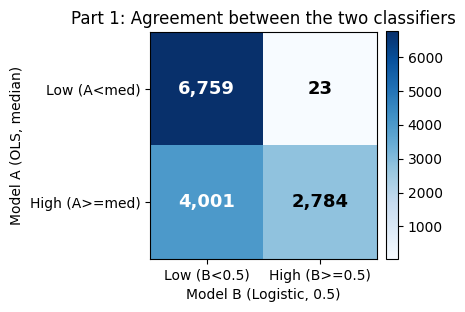

In [6]:
fig,ax=plt.subplots(figsize=(4.6,4.2))
im=ax.imshow(cm,cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j,i,f"{cm[i,j]:,}",ha='center',va='center',
                color='white' if cm[i,j]>cm.max()/2 else 'black',fontsize=13,fontweight='bold')
ax.set_xticks([0,1]); ax.set_xticklabels(['Low (B<0.5)','High (B>=0.5)'])
ax.set_yticks([0,1]); ax.set_yticklabels(['Low (A<med)','High (A>=med)'])
ax.set_xlabel('Model B (Logistic, 0.5)'); ax.set_ylabel('Model A (OLS, median)')
ax.set_title('Part 1: Agreement between the two classifiers')
plt.colorbar(im,fraction=0.046,pad=0.04); plt.tight_layout()
plt.savefig('figures/fig_part1_agreement.png',dpi=150); plt.show()

## 3. Part 2.1 — Simpson's-paradox / subgroup-divergence hunt

We split on **sex** and fit three logistic regressions (statsmodels, for coefficients + 95% CI +
p-values): full training set, Male subgroup (A), Female subgroup (B). Within a subgroup some dummies
become constant or perfectly collinear (e.g. `relationship_Wife` has no males), so a QR-pivot step
prunes the design to a full-rank, identifiable set before each fit. We then scan every shared
predictor for a sign reversal, and failing that report the predictor with the largest **significant**
magnitude divergence between the two subgroups.

In [7]:
def prune_full_rank(Xd):
    Z = Xd.loc[:, Xd.std(axis=0) > 1e-9]
    M = np.column_stack([np.ones(len(Z)), Z.values])
    r = np.linalg.matrix_rank(M)
    if r < M.shape[1]:
        _,_,piv = _qr(M, mode='economic', pivoting=True)
        keep = sorted(piv[:r])
        cols = [c for k,c in enumerate(['__const__']+list(Z.columns)) if k in keep and c!='__const__']
        Z = Z[cols]
    return Z

def coef_table(Xd, yv):
    Xp = prune_full_rank(Xd)
    Xc = sm.add_constant(Xp, has_constant='add')
    res = sm.Logit(yv.values, Xc.values).fit(disp=0, maxiter=300)
    names = list(Xc.columns); ci = res.conf_int()
    return (dict(zip(names,res.params)),
            {n:ci[i,0] for i,n in enumerate(names)}, {n:ci[i,1] for i,n in enumerate(names)},
            dict(zip(names,res.pvalues)))

Xsm_tr = Xsm_s.iloc[tr]; ysm_tr = pd.Series(y[tr], index=Xsm_tr.index)
SEXC='sex_Male'
full_p,full_l,full_u,full_pv = coef_table(Xsm_tr, ysm_tr)
m = Xsm_tr[SEXC]==1; f = Xsm_tr[SEXC]==0
m_p,m_l,m_u,m_pv = coef_table(Xsm_tr[m].drop(columns=[SEXC]), ysm_tr[m])
f_p,f_l,f_u,f_pv = coef_table(Xsm_tr[f].drop(columns=[SEXC]), ysm_tr[f])
R['part2_1']=dict(n_male=int(m.sum()), n_female=int(f.sum()))

shared=[c for c in m_p if c in f_p and c!='const']
scan=pd.DataFrame([dict(pred=c, full=full_p.get(c,np.nan), male=m_p[c], female=f_p[c],
                        male_p=m_pv[c], female_p=f_pv[c], diverg=abs(m_p[c]-f_p[c]),
                        reversal=(np.sign(m_p[c])!=np.sign(f_p[c]) and m_pv[c]<.05 and f_pv[c]<.05))
                   for c in shared]).sort_values('diverg',ascending=False)
rev=scan[scan.reversal]
R['part2_1']['reversals_found']=int(len(rev))
if len(rev):
    key=rev.iloc[0]['pred']; R['part2_1']['chosen_reason']='sign reversal (both subgroups significant)'
else:
    sig=scan[(scan.male_p<.05)&(scan.female_p<.05)].sort_values('diverg',ascending=False)
    key=sig.iloc[0]['pred']; R['part2_1']['chosen_reason']='largest significant magnitude divergence (no clean sign reversal)'
R['part2_1']['key_predictor']=key

def pack(c):
    return dict(coef_full=round(float(full_p.get(c,np.nan)),4), ci_full=[round(float(full_l.get(c,np.nan)),4),round(float(full_u.get(c,np.nan)),4)], p_full=float(full_pv.get(c,np.nan)),
                coef_male=round(float(m_p[c]),4), ci_male=[round(float(m_l[c]),4),round(float(m_u[c]),4)], p_male=float(m_pv[c]),
                coef_female=round(float(f_p[c]),4), ci_female=[round(float(f_l[c]),4),round(float(f_u[c]),4)], p_female=float(f_pv[c]))
R['part2_1']['key_stats']=pack(key)
R['part2_1']['top_divergences']=scan.head(8)[['pred','full','male','female','diverg']].round(4).to_dict('records')

print("subgroup sizes  male:",R['part2_1']['n_male']," female:",R['part2_1']['n_female'])
print("sign reversals found:",R['part2_1']['reversals_found'],"->",R['part2_1']['chosen_reason'])
print("KEY PREDICTOR:",key)
ks=R['part2_1']['key_stats']
print(f"  full   coef={ks['coef_full']:+.3f}  CI={ks['ci_full']}")
print(f"  MALE   coef={ks['coef_male']:+.3f}  CI={ks['ci_male']}")
print(f"  FEMALE coef={ks['coef_female']:+.3f}  CI={ks['ci_female']}")

subgroup sizes  male: 21279  female: 10376
sign reversals found: 0 -> largest significant magnitude divergence (no clean sign reversal)
KEY PREDICTOR: marital-status_Married-civ-spouse
  full   coef=+2.104  CI=[1.5775, 2.63]
  MALE   coef=+1.405  CI=[0.6894, 2.1215]
  FEMALE coef=+3.183  CI=[2.348, 4.0189]


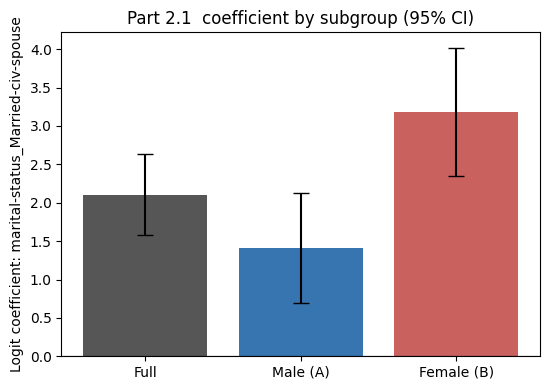

In [8]:
labels=['Full','Male (A)','Female (B)']
vals=[full_p.get(key,np.nan),m_p[key],f_p[key]]
los=[full_l.get(key,np.nan),m_l[key],f_l[key]]; his=[full_u.get(key,np.nan),m_u[key],f_u[key]]
err=[[v-l for v,l in zip(vals,los)],[h-v for v,h in zip(vals,his)]]
fig,ax=plt.subplots(figsize=(5.6,4))
ax.bar(labels,vals,yerr=err,capsize=6,color=['#444','#2066a8','#c3514e'],alpha=.9)
ax.axhline(0,color='k',lw=.8); ax.set_ylabel(f'Logit coefficient: {key}')
ax.set_title("Part 2.1  coefficient by subgroup (95% CI)")
plt.tight_layout(); plt.savefig('figures/fig_part2_1_simpson.png',dpi=150); plt.show()

## 4. Part 2.2 — Omitted-variable bias

We deliberately drop **`relationship`** — the household-role variable whose levels (`Husband`,
`Wife`, …) are themselves sex-encoded and marriage-encoded, making it a textbook confounder of the
sex→income relationship. We compare the full model with a reduced model that omits all `relationship`
dummies and track six coefficients before/after.

In [9]:
rel_cols=[c for c in Xsm_tr.columns if c.startswith('relationship_')]
R['part2_2']=dict(omitted_variable='relationship', omitted_dummies=rel_cols)
red_p,red_l,red_u,red_pv = coef_table(Xsm_tr.drop(columns=rel_cols), ysm_tr)

track=[t for t in ['sex_Male','marital-status_Married-civ-spouse','education-num',
                   'hours-per-week','age','capital-gain'] if t in full_p and t in red_p]
ovb=[]
for t in track:
    b,a=full_p[t],red_p[t]; pct=(a-b)/abs(b)*100 if b!=0 else np.nan
    ovb.append(dict(predictor=t, full=round(float(b),4), reduced=round(float(a),4),
                    abs_change=round(float(a-b),4), pct_change=round(float(pct),1),
                    p_full=float(full_pv.get(t,np.nan)), p_reduced=float(red_pv.get(t,np.nan))))
ovb_df=pd.DataFrame(ovb)
R['part2_2']['table']=ovb_df.to_dict('records')
big=ovb_df.reindex(ovb_df['pct_change'].abs().sort_values(ascending=False).index).iloc[0]
R['part2_2']['biggest_shift']={k:(float(v) if isinstance(v,(int,float,np.floating)) else v) for k,v in big.to_dict().items()}
print("omitted variable: relationship")
print(ovb_df[['predictor','full','reduced','pct_change','p_full','p_reduced']].to_string(index=False))
print("biggest shift:", R['part2_2']['biggest_shift']['predictor'], f"{R['part2_2']['biggest_shift']['pct_change']}%")

omitted variable: relationship
                        predictor   full  reduced  pct_change        p_full     p_reduced
                         sex_Male 0.6589   0.1085       -83.5  1.374974e-17  3.825397e-02
marital-status_Married-civ-spouse 2.1037   2.3263        10.6  4.662355e-15 5.650869e-256
                    education-num 0.7073   0.7144         1.0 1.054380e-194 1.428053e-199
                   hours-per-week 0.3528   0.3519        -0.3  1.034493e-72  1.638638e-73
                              age 0.3372   0.3447         2.2  1.285220e-54  1.352861e-58
                     capital-gain 2.3967   2.4179         0.9 2.677660e-202 3.455909e-208
biggest shift: sex_Male -83.5%


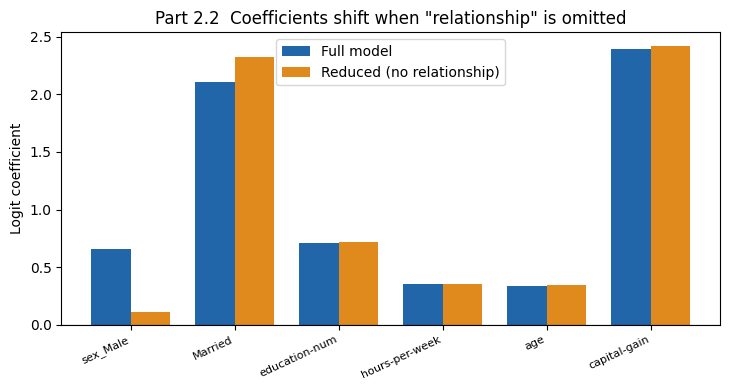

In [10]:
fig,ax=plt.subplots(figsize=(7.4,4)); x=np.arange(len(ovb_df)); w=.38
ax.bar(x-w/2,ovb_df.full,w,label='Full model',color='#2066a8')
ax.bar(x+w/2,ovb_df.reduced,w,label='Reduced (no relationship)',color='#e08a1e')
ax.axhline(0,color='k',lw=.8); ax.set_xticks(x)
ax.set_xticklabels([t.replace('marital-status_','').replace('-civ-spouse','') for t in ovb_df.predictor],rotation=25,ha='right',fontsize=8)
ax.set_ylabel('Logit coefficient'); ax.legend()
ax.set_title('Part 2.2  Coefficients shift when "relationship" is omitted')
plt.tight_layout(); plt.savefig('figures/fig_part2_2_ovb.png',dpi=150); plt.show()

## 5. Part 2.3 — Adversarial (confident-but-wrong) subset

On the test set we collect the cases where Model B is **confidently wrong**: predicted
`P(>50K) ≥ 0.75` but the person actually earns ≤50K (confident false positive), or `P ≤ 0.25` but the
person actually earns >50K (confident false negative). We sample 50 (seed 829) and compare their
demographics to the full test set.

In [11]:
conf_fp=(probB>=0.75)&(yte==0); conf_fn=(probB<=0.25)&(yte==1); adv=conf_fp|conf_fn
R['part2_3']=dict(conf_fp_count=int(conf_fp.sum()), conf_fn_count=int(conf_fn.sum()),
                  total_adv=int(adv.sum()), pct_of_test=round(100*int(adv.sum())/len(te),2))
loc=np.where(adv)[0]; rng=np.random.RandomState(SEED)
sel=loc if len(loc)<=50 else rng.choice(loc,50,replace=False)
R['part2_3']['sample_size']=int(len(sel))
test_rows=df.iloc[te].reset_index(drop=True); A50=test_rows.iloc[sel]

def dist(fr,col,top=None):
    vc=fr[col].value_counts(normalize=True)*100
    return {k:round(float(v),1) for k,v in (vc.head(top) if top else vc).items()}
R['part2_3']['demographics']=dict(
  adv_sex=dist(A50,'sex'), full_sex=dist(test_rows,'sex'),
  adv_race=dist(A50,'race',4), full_race=dist(test_rows,'race',4),
  adv_marital_Married_pct=round(100*float((A50['marital-status']=='Married-civ-spouse').mean()),1),
  full_marital_Married_pct=round(100*float((test_rows['marital-status']=='Married-civ-spouse').mean()),1),
  adv_age_mean=round(float(A50.age.mean()),1), full_age_mean=round(float(test_rows.age.mean()),1),
  adv_hours_mean=round(float(A50['hours-per-week'].mean()),1), full_hours_mean=round(float(test_rows['hours-per-week'].mean()),1),
  adv_capgain_pos_pct=round(100*float((A50['capital-gain']>0).mean()),1),
  full_capgain_pos_pct=round(100*float((test_rows['capital-gain']>0).mean()),1))
fp=test_rows.iloc[np.where(conf_fp)[0]]; fn=test_rows.iloc[np.where(conf_fn)[0]]
R['part2_3']['conf_fp_married_pct']=round(100*float((fp['marital-status']=='Married-civ-spouse').mean()),1)
R['part2_3']['conf_fp_edunum_mean']=round(float(fp['education-num'].mean()),2)
R['part2_3']['conf_fn_capgain_pos_pct']=round(100*float((fn['capital-gain']>0).mean()),1)
R['part2_3']['sample_married_pct']=round(100*float((A50['marital-status']=='Married-civ-spouse').mean()),1)
R['part2_3']['sample_male_pct']=round(100*float((A50['sex']=='Male').mean()),1)

print(f"confident FP (P>=.75, y=0): {R['part2_3']['conf_fp_count']}")
print(f"confident FN (P<=.25, y=1): {R['part2_3']['conf_fn_count']}")
print(f"total confident-wrong: {R['part2_3']['total_adv']}  ({R['part2_3']['pct_of_test']}% of test)")
print("sampled-50 shared traits -> married:",R['part2_3']['sample_married_pct'],"%  male:",R['part2_3']['sample_male_pct'],"%")
print("FP subgroup married%:",R['part2_3']['conf_fp_married_pct'],"| FP mean education-num:",R['part2_3']['conf_fp_edunum_mean'])
print("demographics adv vs full:",json.dumps(R['part2_3']['demographics'],indent=0))

confident FP (P>=.75, y=0): 164
confident FN (P<=.25, y=1): 551
total confident-wrong: 715  (5.27% of test)
sampled-50 shared traits -> married: 70.0 %  male: 82.0 %
FP subgroup married%: 97.0 | FP mean education-num: 12.95
demographics adv vs full: {
"adv_sex": {
"Male": 82.0,
"Female": 18.0
},
"full_sex": {
"Male": 68.2,
"Female": 31.8
},
"adv_race": {
"White": 90.0,
"Amer-Indian-Eskimo": 4.0,
"Black": 4.0,
"Asian-Pac-Islander": 2.0
},
"full_race": {
"White": 86.4,
"Black": 9.2,
"Asian-Pac-Islander": 2.7,
"Amer-Indian-Eskimo": 1.0
},
"adv_marital_Married_pct": 70.0,
"full_marital_Married_pct": 46.6,
"adv_age_mean": 42.2,
"full_age_mean": 38.7,
"adv_hours_mean": 44.4,
"full_hours_mean": 40.9,
"adv_capgain_pos_pct": 8.0,
"full_capgain_pos_pct": 8.3
}


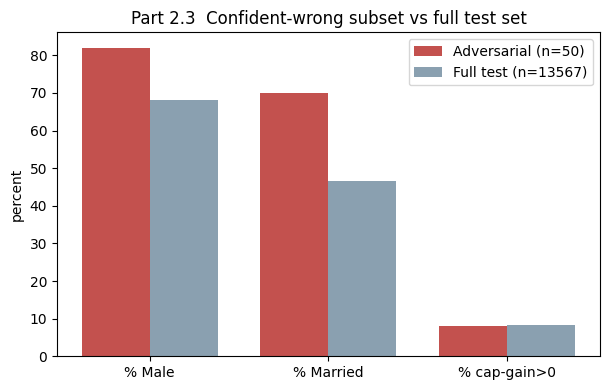

In [12]:
cats=['% Male','% Married','% cap-gain>0']
d=R['part2_3']['demographics']
advv=[d['adv_sex'].get('Male',0),d['adv_marital_Married_pct'],d['adv_capgain_pos_pct']]
fullv=[d['full_sex'].get('Male',0),d['full_marital_Married_pct'],d['full_capgain_pos_pct']]
x=np.arange(3); w=.38
fig,ax=plt.subplots(figsize=(6.2,4))
ax.bar(x-w/2,advv,w,label=f'Adversarial (n={len(sel)})',color='#c3514e')
ax.bar(x+w/2,fullv,w,label=f'Full test (n={len(te)})',color='#8aa0b0')
ax.set_xticks(x); ax.set_xticklabels(cats); ax.set_ylabel('percent'); ax.legend()
ax.set_title('Part 2.3  Confident-wrong subset vs full test set')
plt.tight_layout(); plt.savefig('figures/fig_part2_3_adversarial.png',dpi=150); plt.show()

## 6. Part 2.4 — Fairness trade-off across thresholds

Sensitive attribute = **sex**. Group **A = Female**, Group **B = Male** (A is the lower-base-rate
group, which keeps the ratios inside the 0–1.5 chart range). We sweep the decision threshold over
`{0.05, 0.15, …, 0.95}` and at each compute three ratio metrics (ideal = 1.0):

- **Demographic Parity** `DP = P(Ŷ=1|A)/P(Ŷ=1|B)`
- **Equalized Odds** `EO = min(TPR_A/TPR_B, FPR_A/FPR_B)`
- **Predictive Parity** `PP = precision_A/precision_B`

In [13]:
sexv=test_rows['sex'].values; A=sexv=='Female'; B=sexv=='Male'
ths=[0.05,0.15,0.25,0.35,0.45,0.55,0.65,0.75,0.85,0.95]
def rates(mask,t):
    yh=(probB>=t).astype(int)[mask]; yy=yte[mask]
    tp=((yh==1)&(yy==1)).sum(); fn=((yh==0)&(yy==1)).sum()
    fp=((yh==1)&(yy==0)).sum(); tn=((yh==0)&(yy==0)).sum()
    return (yh.mean(), tp/(tp+fn) if tp+fn else np.nan, fp/(fp+tn) if fp+tn else np.nan,
            tp/(tp+fp) if tp+fp else np.nan)
rows=[]
for t in ths:
    pa,ta,fa,ppa=rates(A,t); pb,tb,fb,ppb=rates(B,t)
    dp=pa/pb if pb>0 else np.nan
    eo=min(ta/tb,fa/fb) if all(np.isfinite([ta,tb,fa,fb])) and tb>0 and fb>0 else np.nan
    pp=ppa/ppb if np.isfinite(ppa) and np.isfinite(ppb) and ppb>0 else np.nan
    rows.append(dict(t=t,DP=dp,EO=eo,PP=pp,posA=round(pa,4),posB=round(pb,4),
                     TPR_A=round(ta,4),TPR_B=round(tb,4),FPR_A=round(fa,4),FPR_B=round(fb,4)))
fair=pd.DataFrame(rows)
R['part2_4']=dict(group_A='Female',group_B='Male',thresholds=ths,
                  base_rate_female=round(float(yte[A].mean()),4), base_rate_male=round(float(yte[B].mean()),4))
R['part2_4']['table']=[{k:(round(float(v),4) if isinstance(v,(int,float,np.floating)) and np.isfinite(v) else None) for k,v in r.items()} for r in rows]
valid=fair.dropna(subset=['DP','EO'])
bdp=valid.loc[valid.DP.idxmax()]; beo=valid.loc[valid.EO.idxmax()]
dDP=(bdp.DP-beo.DP)/beo.DP*100; dEO=(bdp.EO-beo.EO)/beo.EO*100
R['part2_4']['tradeoff_example']=dict(t_best_eo=float(beo.t),DP_at_bestEO=round(float(beo.DP),3),EO_at_bestEO=round(float(beo.EO),3),
    t_best_dp=float(bdp.t),DP_at_bestDP=round(float(bdp.DP),3),EO_at_bestDP=round(float(bdp.EO),3),
    DP_gain_pct=round(float(dDP),1),EO_loss_pct=round(float(dEO),1),tradeoff_cost=round(float(abs(dEO)/abs(dDP)),2))
R['part2_4']['PP_near_one_note']=dict(min_PP=round(float(valid.PP.min()),3),max_PP=round(float(valid.PP.max()),3))
print("base rate  female:",R['part2_4']['base_rate_female']," male:",R['part2_4']['base_rate_male'])
print(fair[['t','DP','EO','PP','posA','posB','TPR_A','TPR_B','FPR_A','FPR_B']].round(3).to_string(index=False))
print("PP range:",R['part2_4']['PP_near_one_note'])
print("trade-off:",R['part2_4']['tradeoff_example'])

base rate  female: 0.1116  male: 0.3129
   t    DP    EO    PP  posA  posB  TPR_A  TPR_B  FPR_A  FPR_B
0.05 0.485 0.459 0.697 0.354 0.730  0.938  0.989  0.281  0.613
0.15 0.323 0.267 0.931 0.186 0.578  0.792  0.941  0.110  0.412
0.25 0.302 0.245 0.967 0.140 0.462  0.703  0.859  0.069  0.281
0.35 0.314 0.281 0.919 0.114 0.365  0.620  0.768  0.051  0.181
0.45 0.312 0.284 0.929 0.092 0.295  0.548  0.673  0.035  0.123
0.55 0.305 0.280 0.940 0.072 0.235  0.458  0.570  0.023  0.083
0.65 0.292 0.223 1.003 0.051 0.176  0.371  0.453  0.011  0.050
0.75 0.285 0.312 0.942 0.034 0.121  0.255  0.339  0.007  0.022
0.85 0.323 0.376 0.964 0.023 0.072  0.187  0.214  0.003  0.007
0.95 0.313 0.710 0.960 0.012 0.037  0.098  0.116  0.001  0.001
PP range: {'min_PP': 0.697, 'max_PP': 1.003}
trade-off: {'t_best_eo': 0.95, 'DP_at_bestEO': 0.313, 'EO_at_bestEO': 0.71, 't_best_dp': 0.05, 'DP_at_bestDP': 0.485, 'EO_at_bestDP': 0.459, 'DP_gain_pct': 55.0, 'EO_loss_pct': -35.3, 'tradeoff_cost': 0.64}


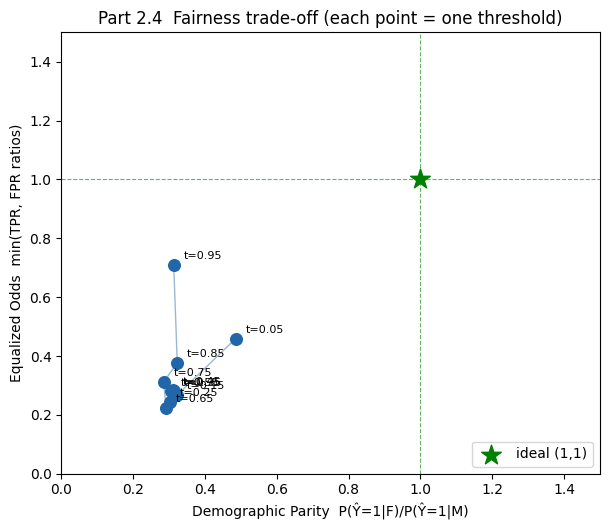

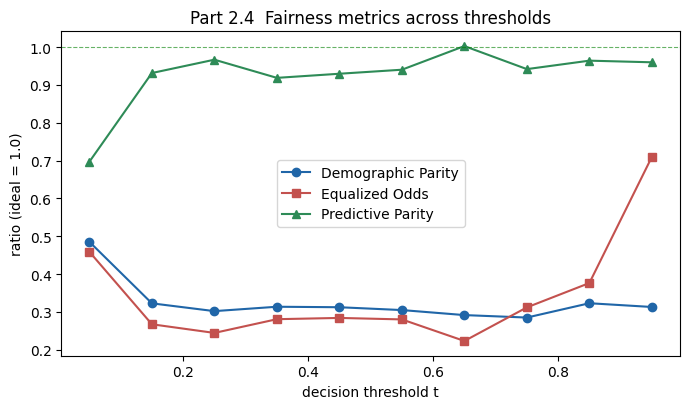

In [14]:
# REQUIRED chart: DP vs EO scatter labelled by threshold
fig,ax=plt.subplots(figsize=(6.2,5.4)); vv=fair.dropna(subset=['DP','EO'])
ax.scatter(vv.DP,vv.EO,s=70,color='#2066a8',zorder=3)
for _,r in vv.iterrows(): ax.annotate(f"t={r.t:.2f}",(r.DP,r.EO),textcoords='offset points',xytext=(7,4),fontsize=8)
ax.plot(vv.DP,vv.EO,color='#9bb8d3',lw=1,zorder=2)
ax.axvline(1,color='green',ls='--',lw=.8,alpha=.6); ax.axhline(1,color='green',ls='--',lw=.8,alpha=.6)
ax.scatter([1],[1],marker='*',s=220,color='green',zorder=4,label='ideal (1,1)')
ax.set_xlim(0,1.5); ax.set_ylim(0,1.5)
ax.set_xlabel('Demographic Parity  P(Ŷ=1|F)/P(Ŷ=1|M)'); ax.set_ylabel('Equalized Odds  min(TPR, FPR ratios)')
ax.set_title('Part 2.4  Fairness trade-off (each point = one threshold)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig('figures/fig_part2_4_tradeoff.png',dpi=150); plt.show()

fig,ax=plt.subplots(figsize=(7,4.2))
ax.plot(fair.t,fair.DP,'-o',label='Demographic Parity',color='#2066a8')
ax.plot(fair.t,fair.EO,'-s',label='Equalized Odds',color='#c3514e')
ax.plot(fair.t,fair.PP,'-^',label='Predictive Parity',color='#2e8b57')
ax.axhline(1,color='green',ls='--',lw=.8,alpha=.6)
ax.set_xlabel('decision threshold t'); ax.set_ylabel('ratio (ideal = 1.0)')
ax.set_title('Part 2.4  Fairness metrics across thresholds'); ax.legend()
plt.tight_layout(); plt.savefig('figures/fig_part2_4_curves.png',dpi=150); plt.show()

## Save all computed numbers

In [15]:
def clean(o):
    if isinstance(o,dict): return {k:clean(v) for k,v in o.items()}
    if isinstance(o,list): return [clean(v) for v in o]
    if isinstance(o,np.integer): return int(o)
    if isinstance(o,np.floating): return (round(float(o),4) if np.isfinite(o) else None)
    if isinstance(o,float) and not np.isfinite(o): return None
    return o
json.dump(clean(R), open('output/results.json','w'), indent=2)
print('Saved output/results.json with', len(R), 'top-level sections.')

Saved output/results.json with 17 top-level sections.
